# Tema 26 · Visión moderna: modelos preentrenados, autoaprendizaje y CLIP

Usar redes que ya vieron millones de imágenes, y conectar imágenes con texto.

Este cuaderno es el tema 26 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/ruta/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/ruta/26-vision-moderna-modelos-preentrenados-autoaprendizaje-y-clip/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

Este tema entrena o usa redes grandes: en Colab, *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU* lo hace mucho más rápido.

Primero, las bibliotecas que este tema necesita y que Colab no trae (o trae en otra versión):

In [ ]:
!pip install -q accelerate==1.15.0 transformers==5.21.0 umap-learn==0.5.12

# Teoría

## La pregunta

Quieres que tu computadora reconozca las cosas de tu mesa: una taza, un cuaderno, tus llaves y tu celular. Sacas 50 fotos de cada una. En el tema «Redes convolucionales» entrenaste una CNN desde cero con 10 000 imágenes de ropa, y con 200 fotos no alcanza: la red tendría que aprender desde cero qué es un borde, una textura, una forma… y además qué es una taza.

Pero hay redes que ya aprendieron a ver con **más de un millón de fotos**, y están publicadas. Igual que en el tema «Reutilizar modelos» hiciste con el texto, puedes tomar una de esas redes y **ajustarla** con tus pocas fotos. Y hay algo todavía más sorprendente: un modelo llamado **CLIP** aprendió a poner fotos y frases en el mismo espacio, así que puede clasificar tus fotos **sin entrenar nada**, solo con frases como «una foto de una taza».

En este tema vas a:

- hacer **transfer learning** con una ResNet preentrenada: entrenar **solo la cabeza** o **ajustar toda la red**, y medir cuántas fotos por clase te ahorra;
- entender el **aprendizaje autosupervisado**: cómo una red aprende a ver sin etiquetas (SimCLR y DINO), y usar sus variables con **k-NN**;
- clasificar fotos con un **Vision Transformer** preentrenado;
- usar **CLIP** para clasificar sin entrenar (*zero-shot*) y para **buscar fotos con texto**;
- leer la **pérdida contrastiva** como una matriz de similitudes.

Necesitas las CNN del tema «Redes convolucionales», los embeddings y la similitud coseno del tema «Embeddings», los parches y el token [CLS] del tema «Atención y transformers», y la idea de congelar y ajustar del tema «Reutilizar modelos». También la función `entrenar` del tema 18.

## Actividad: une la foto con su frase

Aquí hay seis fotos y seis frases. Para cada foto, elige la frase que la describe y pulsa «Comparar con CLIP». Vas a ver la **matriz de similitudes** que calculó CLIP: una fila por foto, una columna por frase, y en cada casilla qué tan parecidos son la foto y la frase para el modelo.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/ruta/26-vision-moderna-modelos-preentrenados-autoaprendizaje-y-clip/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Haz tus seis parejas y compáralas con las de CLIP. ¿En cuántas coinciden?
2. Mira la diagonal (las parejas correctas, con borde coral). ¿Es el número más alto de cada fila? ¿Por cuánto le gana al segundo?
3. Mueve la **temperatura** τ. Con τ grande, las probabilidades de cada fila se reparten; con τ chica, casi todo se va a la casilla más alta. ¿Qué pasa con la pérdida?
4. CLIP aprendió τ = 0,01. Con ese valor, ¿cuánta probabilidad le da a cada frase correcta?

Así entrenaron a CLIP: con lotes de miles de fotos y sus textos, la pérdida pide que en esta matriz **la diagonal suba y todo lo demás baje**. Al final del tema vas a calcular esa pérdida en Python.

## Los datos: la Tierra vista desde un satélite

Para medir con cuidado necesitamos un dataset pequeño, con pocas clases y con una licencia que cubra las imágenes. Usaremos **EuroSAT**: 27 000 fotos de 64 × 64 píxeles tomadas por los satélites **Sentinel-2** del programa europeo Copernicus. Cada píxel mide 10 m de lado, así que cada foto cubre un cuadrado de 640 m × 640 m. Elegimos cuatro de sus diez clases (bosque, autopista, zona residencial y río) y, para que todo corra en un par de minutos sin GPU, **100 fotos por clase para entrenar y otras 100 para probar**.

**Fuente de los datos.** EuroSAT de Helber, Bischke, Dengel y Borth (2019), con licencia MIT. Contiene datos modificados de Copernicus Sentinel (2015–2018), de uso libre según el [aviso legal de Sentinel](https://sentinel.esa.int/documents/247904/690755/Sentinel_Data_Legal_Notice).

Fotos: 27000   clases: 10
['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial']
['Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Entrenamiento: 400   validación: 400


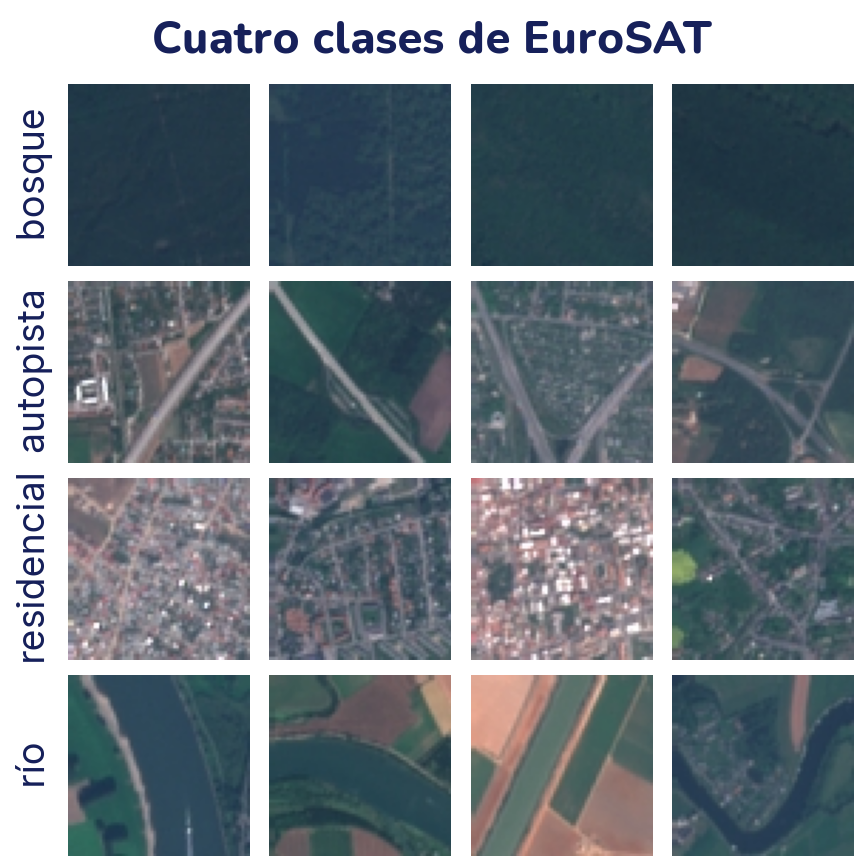

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torchvision.datasets import EuroSAT

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

# La primera vez descarga 94 MB a la carpeta datos/
eurosat = EuroSAT(root="datos", download=True)
print("Fotos:", len(eurosat), "  clases:", len(eurosat.classes))
print(eurosat.classes[:5])
print(eurosat.classes[5:])

CLASES = ["Forest", "Highway", "Residential", "River"]
NOMBRES = ["bosque", "autopista", "residencial", "río"]
etiquetas = np.array(eurosat.targets)
rng = np.random.default_rng(42)
idx_ent, idx_val = [], []
for clase in CLASES:
    de_la_clase = np.flatnonzero(etiquetas == eurosat.class_to_idx[clase])
    elegidas = rng.choice(de_la_clase, size=200, replace=False)
    idx_ent += list(elegidas[:100])
    idx_val += list(elegidas[100:])

# Fotos PIL de 64 × 64, ordenadas por clase: 100 de cada una
fotos_ent = [eurosat[i][0] for i in idx_ent]
fotos_val = [eurosat[i][0] for i in idx_val]
y_ent = torch.arange(4).repeat_interleave(100)
y_val = torch.arange(4).repeat_interleave(100)
print("Entrenamiento:", len(fotos_ent), "  validación:", len(fotos_val))

fig, ejes = plt.subplots(4, 4, figsize=(4.8, 4.8))
for fila in range(4):
    for col in range(4):
        eje = ejes[fila, col]
        eje.imshow(fotos_ent[fila * 100 + col])
        eje.set_xticks([])
        eje.set_yticks([])
        eje.spines[:].set_visible(False)
    ejes[fila, 0].set_ylabel(NOMBRES[fila])
fig.suptitle("Cuatro clases de EuroSAT")
plt.show()

A simple vista las clases se distinguen, pero no siempre: un río angosto y una autopista son las dos una franja que cruza la foto, y una autopista suele pasar junto a casas.

## Redes que ya vieron millones de fotos

**ImageNet** es una colección de 1,28 millones de fotos de entrenamiento etiquetadas en 1000 clases (perros de 120 razas, instrumentos, vehículos, comidas…). Muchas redes famosas se entrenaron con ella y sus pesos están publicados. Una red que aprendió a separar 1000 clases tuvo que aprender, en sus primeras capas, bordes y texturas, y en las siguientes, partes y formas: justo lo que cualquier problema de visión necesita.

Vamos a usar **ResNet-18** (2015), de 11,7 millones de parámetros. Su idea clave son las **conexiones residuales**: cada bloque no reemplaza su entrada, sino que le **suma** una corrección.

$$\text{salida} = F ( x ) + x$$

Aquí *F* son dos convoluciones como las del tema «Redes convolucionales». Si un bloque no tiene nada útil que agregar, le basta con dejar *F* cerca de cero, y la señal (y el gradiente, al entrenar) pasa intacta por el atajo. Es la misma suma residual del bloque transformer del tema «Atención y transformers», y es lo que permitió entrenar redes de más de cien capas. Otra familia que vas a encontrar es **MobileNet**, diseñada para celulares: separa cada convolución en dos más baratas y queda con pocos parámetros (`mobilenet_v3_small` tiene 2,5 millones).

Con los pesos viene la forma correcta de **preparar** las fotos: `pesos.transforms()`. Hay que usarla siempre, porque la red aprendió con fotos de ese tamaño y normalizadas con esa media y esa desviación; si le das las fotos de otra forma, sus filtros reciben números que nunca vieron.

In [ ]:
from torchvision.models import resnet18, ResNet18_Weights

# Pesos de ImageNet: la primera vez descarga 45 MB
pesos = ResNet18_Weights.DEFAULT
red = resnet18(weights=pesos)
total = sum(p.numel() for p in red.parameters())
print(f"Parámetros: {total:,}".replace(",", " "))
print("Última capa:", red.fc)

preparar = pesos.transforms()
print(preparar)

x_ent = torch.stack([preparar(f) for f in fotos_ent])
x_val = torch.stack([preparar(f) for f in fotos_val])
print("Tensores:", tuple(x_ent.shape), tuple(x_val.shape))

Parámetros: 11 689 512
Última capa: Linear(in_features=512, out_features=1000, bias=True)
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
Tensores: (400, 3, 224, 224) (400, 3, 224, 224)


La última capa, `fc`, es la **cabeza**: convierte los 512 números que resumen la foto en 1000 puntajes, uno por clase de ImageNet. Las transformaciones agrandan cada foto de 64 a 256 píxeles, recortan el centro de 224 × 224 (se pierde un borde de 16 píxeles de los 256) y normalizan cada canal de color.

Hay dos formas de reutilizar la red, como en el tema «Reutilizar modelos»:

1. **Solo la cabeza.** Se **congela** toda la red (sus pesos no cambian) y se entrena una cabeza nueva de 512 → 4. La red funciona como un **extractor de variables**.
2. **Ajuste completo.** Se cambia la cabeza y se entrenan **todos** los pesos, con una tasa de aprendizaje pequeña para no borrar lo que la red ya sabía.

### La función `entrenar` del tema 18

Para entrenar usamos la función `entrenar` del tema 18, sin cambiar nada. Si no la tienes a mano, cópiala en tu cuaderno tal como está aquí; en el tema 18 se explica línea por línea.

In [ ]:
import torch
from torch import nn


def evaluar(modelo, cargador, funcion_perdida, dispositivo="cpu"):
    """Pérdida media y exactitud de `modelo` sobre `cargador`."""
    modelo.eval()
    suma, aciertos, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in cargador:
            x, y = x.to(dispositivo), y.to(dispositivo)
            salida = modelo(x)
            suma += funcion_perdida(salida, y).item() * len(y)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            total += len(y)
    return suma / total, aciertos / total


def entrenar(modelo, cargador_ent, cargador_val, epocas, optimizador,
             funcion_perdida=None, planificador=None, dispositivo="cpu",
             mostrar=True):
    """Entrena `modelo` y devuelve el historial de cada época."""
    if funcion_perdida is None:
        funcion_perdida = nn.CrossEntropyLoss()
    modelo.to(dispositivo)
    historial = {"perdida_ent": [], "exactitud_ent": [],
                 "perdida_val": [], "exactitud_val": []}
    for epoca in range(1, epocas + 1):
        modelo.train()
        suma, aciertos, total = 0.0, 0, 0
        for x, y in cargador_ent:
            x, y = x.to(dispositivo), y.to(dispositivo)
            optimizador.zero_grad()
            salida = modelo(x)
            perdida = funcion_perdida(salida, y)
            perdida.backward()
            optimizador.step()
            suma += perdida.item() * len(y)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            total += len(y)
        if planificador is not None:
            planificador.step()
        perdida_val, exactitud_val = evaluar(
            modelo, cargador_val, funcion_perdida, dispositivo)
        historial["perdida_ent"].append(suma / total)
        historial["exactitud_ent"].append(aciertos / total)
        historial["perdida_val"].append(perdida_val)
        historial["exactitud_val"].append(exactitud_val)
        if mostrar:
            print(f"Época {epoca}: pérdida {suma / total:.3f}, "
                  f"validación {perdida_val:.3f}, "
                  f"exactitud de validación {exactitud_val:.3f}")
    return historial

Las 400 fotos que no son de entrenamiento son de **validación**: con ellas miramos cómo va el entrenamiento y comparamos las formas de reutilizar la red. La **prueba** (tema 7) son otras 100 fotos que nadie mira hasta el final: la usamos una sola vez, con el modelo que elijamos.

### Primera forma: solo la cabeza

Si la red está congelada, cada foto da siempre los mismos 512 números. Entonces no hace falta pasarla por la red en cada época: la pasamos **una sola vez**, guardamos sus variables y entrenamos la cabeza sobre ellas. Es lo mismo que congelar (`requires_grad = False`), pero mucho más rápido. Para quitar la cabeza de ImageNet la cambiamos por `nn.Identity()`, una capa que devuelve lo mismo que recibe.

In [ ]:
from torch.utils.data import DataLoader, TensorDataset

# Sin la cabeza de ImageNet, la red devuelve 512 números por foto
red.fc = nn.Identity()
red = red.to(device).eval()


def variables(red, x, lote=100):
    """Pasa x por la red congelada, de a `lote` fotos."""
    partes = []
    with torch.no_grad():
        for i in range(0, len(x), lote):
            partes.append(red(x[i:i + lote].to(device)).cpu())
    return torch.cat(partes)


v_ent = variables(red, x_ent)
v_val = variables(red, x_val)
print("Variables:", tuple(v_ent.shape), tuple(v_val.shape))

torch.manual_seed(0)
cabeza = nn.Linear(512, 4)
cargador_ent = DataLoader(TensorDataset(v_ent, y_ent), batch_size=32,
                          shuffle=True,
                          generator=torch.Generator().manual_seed(0))
cargador_val = DataLoader(TensorDataset(v_val, y_val), batch_size=400)
optimizador = torch.optim.Adam(cabeza.parameters(), lr=1e-3)
hist_cabeza = entrenar(cabeza, cargador_ent, cargador_val, epocas=30,
                       optimizador=optimizador, dispositivo=device,
                       mostrar=False)
exactitud = hist_cabeza["exactitud_val"]
print("Parámetros entrenables:",
      sum(p.numel() for p in cabeza.parameters()))
print(f"Exactitud de validación: época 1 {exactitud[0]:.3f}, "
      f"época 10 {exactitud[9]:.3f}, época 30 {exactitud[-1]:.3f}")

Variables: (400, 512) (400, 512)
Parámetros entrenables: 2052
Exactitud de validación: época 1 0.760, época 10 0.915, época 30 0.938


Entrenando solo 2052 números (512 · 4 pesos y 4 sesgos), la red clasifica bien unas 94 de cada 100 fotos que no vio. Y eso que **ImageNet no tiene fotos satelitales**: las variables que la red aprendió con perros y autos sirven también para bosques y ríos. Cada época tarda una fracción de segundo, porque la cabeza es diminuta.

### Segunda forma: ajustar toda la red

Ahora cargamos la red otra vez, le ponemos una cabeza nueva de 4 clases y entrenamos sus 11 millones de parámetros. La tasa de aprendizaje es **diez veces más chica** (0,0001): los pesos ya son buenos y solo queremos retocarlos. Con una tasa grande, los primeros lotes, que llegan con una cabeza al azar, darían gradientes enormes que estropearían los filtros aprendidos.

In [ ]:
torch.manual_seed(0)
completa = resnet18(weights=pesos)
completa.fc = nn.Linear(512, 4)          # cabeza nueva, 4 clases
cargador_ent = DataLoader(TensorDataset(x_ent, y_ent), batch_size=32,
                          shuffle=True,
                          generator=torch.Generator().manual_seed(0))
cargador_val = DataLoader(TensorDataset(x_val, y_val), batch_size=100)
optimizador = torch.optim.Adam(completa.parameters(), lr=1e-4)
hist_completa = entrenar(completa, cargador_ent, cargador_val, epocas=2,
                         optimizador=optimizador, dispositivo=device)
entrenables = sum(p.numel() for p in completa.parameters()
                  if p.requires_grad)
print(f"Parámetros entrenables: {entrenables:,}".replace(",", " "))

Época 1: pérdida 0.642, validación 0.324, exactitud de validación 0.897
Época 2: pérdida 0.074, validación 0.125, exactitud de validación 0.963
Parámetros entrenables: 11 178 564


Con solo dos épocas, el ajuste completo llega a 96,3 %, por encima de la cabeza sola. Ajustar todos los filtros deja que la red se acomode a algo que ImageNet no tenía: texturas vistas desde arriba. El precio es el tiempo: cada época pasa las 400 fotos por toda la red, hacia adelante y hacia atrás. En esta computadora sin GPU, las dos épocas tardaron cerca de un minuto, contra un par de segundos de las 30 épocas de la cabeza.

Con 400 fotos de validación, el ajuste completo le ganó a la cabeza sola, así que lo elegimos. Recién ahora lo medimos **una sola vez** con la prueba: 25 fotos nuevas de cada clase, que no se usaron ni para entrenar ni para comparar.

In [ ]:
# La prueba: 25 fotos nuevas por clase, que nadie miró hasta ahora
usadas = set(idx_ent) | set(idx_val)
rng_prueba = np.random.default_rng(0)
idx_pru = []
for clase in CLASES:
    de_la_clase = np.flatnonzero(etiquetas == eurosat.class_to_idx[clase])
    libres = [i for i in de_la_clase if i not in usadas]
    idx_pru += list(rng_prueba.choice(libres, size=25, replace=False))
x_pru = torch.stack([preparar(eurosat[i][0]) for i in idx_pru])
y_pru = torch.arange(4).repeat_interleave(25)
cargador_pru = DataLoader(TensorDataset(x_pru, y_pru), batch_size=100)
_, exactitud_pru = evaluar(completa, cargador_pru, nn.CrossEntropyLoss(),
                           device)
print(f"Exactitud de prueba (una sola vez): {exactitud_pru:.3f}")

Exactitud de prueba (una sola vez): 0.950


Con 100 fotos que nunca vio, el ajuste completo acierta 95 de cada 100, cerca del 96,3 % de validación. Esta es la cifra que se reporta del modelo elegido; si ahora cambiáramos algo por haberla visto, la prueba dejaría de ser honesta.

Entre los dos extremos hay un punto medio: congelar las primeras capas (bordes y texturas, que sirven para todo) y ajustar solo las últimas y la cabeza. Lo pruebas en los ejercicios.

### ¿Cuántas fotos hacen falta?

La gran promesa del transfer learning es necesitar **menos fotos**. Midámoslo: entrenamos con 5, 10, 20, 50 y 100 fotos por clase de dos formas.

- **Desde cero**: una CNN pequeña como las del tema «Redes convolucionales», con BatchNorm, sobre las fotos reducidas a 32 × 32. Como aumentación, volteamos las fotos al azar: una foto satelital volteada sigue siendo una foto válida de lo mismo. Con 5 fotos por clase, una época es un solo lote, así que en lugar de épocas contamos **pasos**: todas las corridas dan 300 pasos con lotes de 32 fotos sorteadas.
- **Transfer**: las variables de ResNet-18 que ya calculamos, con una cabeza lineal. Para entrenar tantas cabezas rápido usamos `LogisticRegression` de scikit-learn (tema 8), que es la misma cabeza lineal. A una cabeza lineal sobre variables congeladas también se le llama **sonda lineal**.

  5 por clase:  desde cero 0.632   transfer 0.785
 10 por clase:  desde cero 0.705   transfer 0.833
 20 por clase:  desde cero 0.788   transfer 0.897
 50 por clase:  desde cero 0.817   transfer 0.927
100 por clase:  desde cero 0.825   transfer 0.927


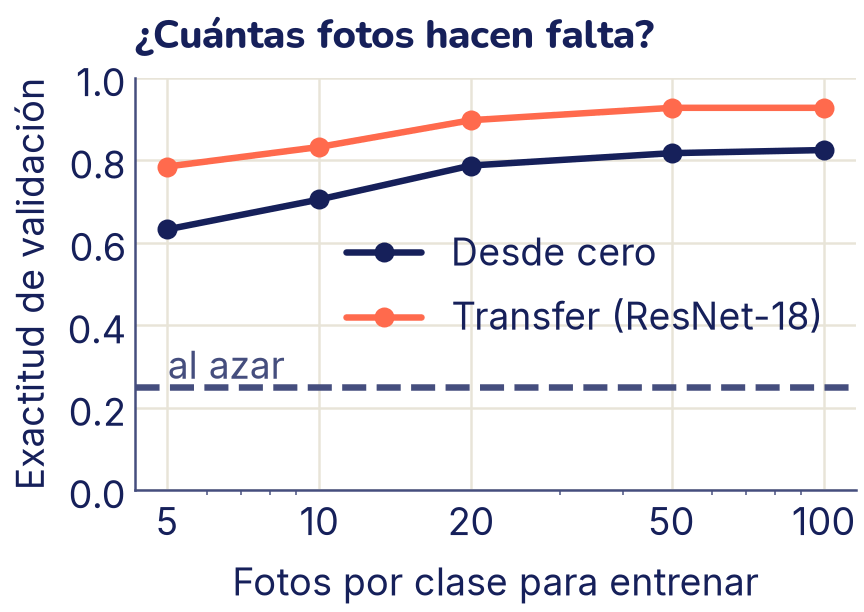

In [ ]:
from sklearn.linear_model import LogisticRegression
from torchvision.transforms.functional import to_tensor

# Fotos originales de 64 × 64, normalizadas y reducidas a 32 × 32
r_ent = torch.stack([to_tensor(f) for f in fotos_ent])
r_val = torch.stack([to_tensor(f) for f in fotos_val])
media = r_ent.mean(dim=(0, 2, 3), keepdim=True)
desv = r_ent.std(dim=(0, 2, 3), keepdim=True)
r_ent = nn.functional.avg_pool2d((r_ent - media) / desv, 2)
r_val = nn.functional.avg_pool2d((r_val - media) / desv, 2)


def cnn_pequena():
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, 4))


def desde_cero(x, y, pasos=300):
    """Entrena una CNN nueva y devuelve su exactitud de validación."""
    torch.manual_seed(0)
    modelo = cnn_pequena().to(device)
    opt = torch.optim.Adam(modelo.parameters(), lr=1e-3)
    g = torch.Generator().manual_seed(0)
    modelo.train()
    for _ in range(pasos):
        i = torch.randint(len(x), (32,), generator=g)
        xb, yb = x[i], y[i]
        # Aumentación: voltear horizontal y verticalmente al azar
        if torch.rand(1, generator=g) < 0.5:
            xb = xb.flip(3)
        if torch.rand(1, generator=g) < 0.5:
            xb = xb.flip(2)
        opt.zero_grad()
        perdida = nn.functional.cross_entropy(modelo(xb.to(device)),
                                              yb.to(device))
        perdida.backward()
        opt.step()
    modelo.eval()
    with torch.no_grad():
        pred = modelo(r_val.to(device)).argmax(dim=1).cpu()
    return (pred == y_val).float().mean().item()


por_clase = [5, 10, 20, 50, 100]
exact_cero, exact_transfer = [], []
for n in por_clase:
    # Las primeras n fotos de cada clase
    sel = torch.cat([torch.arange(k * 100, k * 100 + n) for k in range(4)])
    sonda = LogisticRegression(max_iter=2000)
    sonda.fit(v_ent[sel].numpy(), y_ent[sel].numpy())
    exact_transfer.append(sonda.score(v_val.numpy(), y_val.numpy()))
    exact_cero.append(desde_cero(r_ent[sel], y_ent[sel]))
    print(f"{n:3d} por clase:  desde cero {exact_cero[-1]:.3f}   "
          f"transfer {exact_transfer[-1]:.3f}")

plt.plot(por_clase, exact_cero, "o-", color="C0", label="Desde cero")
plt.plot(por_clase, exact_transfer, "o-", color="C1",
         label="Transfer (ResNet-18)")
plt.axhline(0.25, color="C2", linestyle="--")
plt.text(5, 0.27, "al azar", color="C2")
plt.xscale("log")
plt.xticks(por_clase, [str(n) for n in por_clase])
plt.ylim(0, 1)
plt.xlabel("Fotos por clase para entrenar")
plt.ylabel("Exactitud de validación")
plt.title("¿Cuántas fotos hacen falta?")
plt.legend(loc="center right")
plt.show()

Con **5 fotos por clase**, el transfer (78,5 %) queda cerca de lo que la CNN desde cero logra con **100** (82,5 %), y con 20 fotos por clase ya la supera. Esa es la razón por la que, en la práctica, casi nadie entrena una red de visión desde cero: se parte de una preentrenada. La CNN desde cero sigue mejorando con más fotos y, con miles, podría alcanzar al transfer; pero rara vez tienes miles de fotos etiquetadas de tu problema.

## Aprender sin etiquetas

ResNet-18 aprendió a ver con 1,28 millones de fotos **etiquetadas a mano**. Etiquetar es caro, y en internet hay miles de millones de fotos sin etiqueta. ¿Puede una red aprender a ver sin que nadie le diga qué hay en cada foto? Sí: es el **aprendizaje autosupervisado**. La red inventa su propia tarea a partir de los datos, como BERT en el tema «Reutilizar modelos», que aprendía a leer tapando palabras.

### SimCLR: dos vistas de la misma foto

La idea de **SimCLR** (2020) es esta: toma una foto y fabrica dos versiones distintas con aumentación (recortar un pedazo, voltear, cambiar colores). Las dos siguen mostrando lo mismo. La red convierte cada versión en un vector y aprende con una sola regla:

- los vectores de las **dos vistas de la misma foto** deben quedar **cerca**;
- los vectores de **fotos distintas** deben quedar **lejos**.

Para cumplirla, la red tiene que fijarse en lo que no cambia con la aumentación (la forma de una zapatilla, el cuello de una camisa) e ignorar lo que sí cambia (la posición, el tamaño). Eso es aprender a ver.

La regla se convierte en una pérdida con la **matriz de similitudes** de la actividad. Con un lote de *N* fotos hay 2*N* vistas. Para cada vista se calcula la similitud coseno con las otras 2*N* − 1, se divide por una temperatura τ y se aplica softmax: la vista tiene que «adivinar» cuál de todas es su pareja. La pérdida es la entropía cruzada de esa adivinanza, la misma de siempre, con la pareja como respuesta correcta. Si la red no sabe nada, adivina al azar y la pérdida vale ln(2*N* − 1).

Vamos a probarlo en pequeño, **solo para ilustrar**: 4000 prendas de FashionMNIST (las del tema «Redes convolucionales»), sin usar sus etiquetas, y **una sola época**.

In [ ]:
import torch.nn.functional as F
from torchvision import datasets, transforms

moda = datasets.FashionMNIST(root="datos", train=True, download=True)
g = torch.Generator().manual_seed(0)
elegidas = torch.randperm(len(moda), generator=g)[:4000]
# Solo las imágenes: las etiquetas no se usan
x_moda = moda.data[elegidas].float().div(255).unsqueeze(1)

aumentar = transforms.Compose([
    transforms.RandomResizedCrop(28, scale=(0.4, 1.0)),
    transforms.RandomHorizontalFlip()])


def vista(x):
    """Una versión aumentada distinta de cada imagen del lote."""
    return torch.stack([aumentar(im) for im in x])


def perdida_contrastiva(z1, z2, tau=0.5):
    """z1[i] y z2[i] son las dos vistas de la foto i."""
    z = F.normalize(torch.cat([z1, z2]), dim=1)
    sim = z @ z.T / tau                   # similitud coseno / tau
    sim.fill_diagonal_(float("-inf"))     # nadie es su propia pareja
    n = len(z1)
    pareja = torch.cat([torch.arange(n, 2 * n), torch.arange(n)])
    return F.cross_entropy(sim, pareja)


torch.manual_seed(0)
codificador = nn.Sequential(
    nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(), nn.Linear(64 * 7 * 7, 128))
proyector = nn.Sequential(nn.ReLU(), nn.Linear(128, 64))

# Un lote fijo de 256 imágenes con sus dos vistas, para medir
v1, v2 = vista(x_moda[:256]), vista(x_moda[:256])


def medir():
    codificador.eval()
    with torch.no_grad():
        z1, z2 = proyector(codificador(v1)), proyector(codificador(v2))
        sim = F.normalize(z1, dim=1) @ F.normalize(z2, dim=1).T
        acierto = (sim.argmax(dim=1) == torch.arange(256)).float().mean()
    return perdida_contrastiva(z1, z2).item(), acierto.item()


print(f"Pérdida si adivina al azar: ln(511) = {np.log(511):.2f}")
perdida, acierto = medir()
print(f"Antes:   pérdida {perdida:.2f}, encuentra su pareja {acierto:.1%}")

parametros = list(codificador.parameters()) + list(proyector.parameters())
opt = torch.optim.Adam(parametros, lr=1e-3)
codificador.train()
orden = torch.randperm(len(x_moda), generator=g)
for i in range(0, len(x_moda), 256):         # una época: 16 lotes
    x = x_moda[orden[i:i + 256]]
    perdida = perdida_contrastiva(proyector(codificador(vista(x))),
                                  proyector(codificador(vista(x))))
    opt.zero_grad()
    perdida.backward()
    opt.step()
perdida, acierto = medir()
print(f"Después: pérdida {perdida:.2f}, encuentra su pareja {acierto:.1%}")

Pérdida si adivina al azar: ln(511) = 6.24
Antes:   pérdida 6.21, encuentra su pareja 12.1%
Después: pérdida 5.13, encuentra su pareja 21.1%


Antes de entrenar, la pérdida está muy cerca de la del azar. Tras 16 lotes ya baja, y la red encuentra la pareja de cada vista entre 256 candidatas más veces que al principio (al azar acertaría 1 de cada 256, el 0,4 %). Para que estos vectores sirvan de verdad para clasificar, SimCLR se entrena **cientos de épocas** con lotes de miles de fotos: lo que hicimos es la idea, no el resultado. Por eso, en la práctica, se usan modelos que ya alguien entrenó así. El **proyector** es un detalle de SimCLR: la pérdida se calcula sobre su salida, pero después se usa la salida del codificador, que guarda más información.

### DINOv2: un modelo autosupervisado listo para usar

**DINO** (2021) y **DINOv2** (2023), de Meta, aprenden sin etiquetas con otra variante de la misma idea: un ViT «alumno» mira recortes pequeños de una foto y tiene que dar la misma salida que un ViT «maestro» que mira la foto entera. El maestro no se entrena con gradientes: es un promedio de las versiones anteriores del alumno. DINOv2 aprendió así con 142 millones de fotos sin etiquetas.

Usaremos `facebook/dinov2-small` (22 millones de parámetros, licencia Apache-2.0). Su salida `pooler_output` es un vector de 384 números por foto: el token [CLS] del tema «Atención y transformers» al final de la red. Para ver si esos vectores sirven, no entrenamos nada: clasificamos cada foto de validación con **k-NN** (tema 8), por votación de sus 5 vecinas más parecidas del entrenamiento, con la similitud coseno. Si las fotos de la misma clase quedan cerca, k-NN acierta.

In [ ]:
from transformers import AutoModel, AutoImageProcessor
from sklearn.neighbors import KNeighborsClassifier

DINO = "facebook/dinov2-small"
proc_dino = AutoImageProcessor.from_pretrained(DINO)
dino = AutoModel.from_pretrained(DINO).to(device).eval()


def variables_dino(fotos, lote=50):
    partes = []
    with torch.no_grad():
        for i in range(0, len(fotos), lote):
            x = proc_dino(images=fotos[i:i + lote], return_tensors="pt")
            partes.append(dino(**x.to(device)).pooler_output.cpu())
    return torch.cat(partes)


d_ent = variables_dino(fotos_ent)
d_val = variables_dino(fotos_val)
print("Variables de DINOv2:", tuple(d_ent.shape))

for nombre, a, b in [("DINOv2", d_ent, d_val), ("ResNet-18", v_ent, v_val)]:
    knn = KNeighborsClassifier(n_neighbors=5, metric="cosine")
    knn.fit(a.numpy(), y_ent.numpy())
    print(f"k-NN (k = 5) con {nombre}: "
          f"{knn.score(b.numpy(), y_val.numpy()):.3f}")

Variables de DINOv2: (400, 384)
k-NN (k = 5) con DINOv2: 0.907
k-NN (k = 5) con ResNet-18: 0.890


Sin entrenar nada y sin que DINOv2 haya visto nunca una etiqueta, el 91 % de las fotos de validación quedan bien clasificadas por la votación de sus 5 vecinas. Las variables de ResNet-18, que sí aprendió con etiquetas de ImageNet, quedan un poco por detrás con el mismo k-NN. Dibujemos las 800 fotos con UMAP (tema «Reducir dimensiones»), con los ríos en coral:

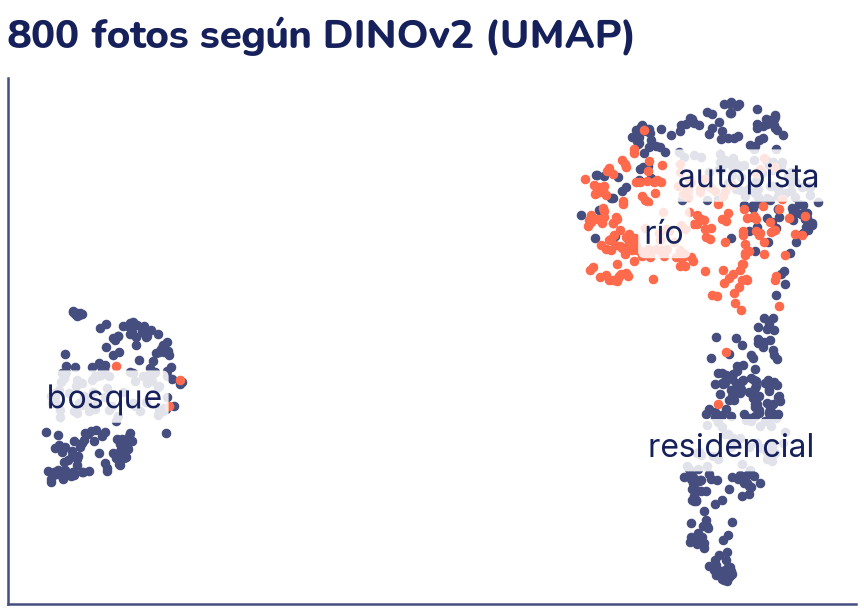

In [ ]:
import umap

todas = torch.cat([d_ent, d_val]).numpy()
y_todas = torch.cat([y_ent, y_val]).numpy()
plano = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine",
                  random_state=0, n_jobs=1).fit_transform(todas)

fig, eje = plt.subplots()
for k, nombre in enumerate(NOMBRES):
    puntos = plano[y_todas == k]
    color = "C1" if nombre == "río" else "C2"
    eje.scatter(puntos[:, 0], puntos[:, 1], s=8, color=color)
    cx, cy = np.median(puntos, axis=0)
    eje.text(cx, cy, nombre, ha="center", va="center", fontsize=13,
             color="C0",
             bbox=dict(boxstyle="round,pad=0.2", facecolor="white",
                       edgecolor="none", alpha=0.85))
eje.set_xticks([])
eje.set_yticks([])
eje.set_title("800 fotos según DINOv2 (UMAP)")
plt.show()

UMAP nunca vio las etiquetas (solo las usamos para pintar), y aun así el bosque queda muy aparte y las zonas residenciales forman su propio grupo. Ríos y autopistas, en cambio, comparten un grupo: las dos son una franja que cruza la foto. Valen las advertencias del tema «Reducir dimensiones»: el plano distorsiona, y en los 384 números originales k-NN separó bien la mayoría de las fotos.

## Un transformer que mira fotos: ViT

En el tema «Atención y transformers» partiste una foto en parches de 16 × 16 y los trataste como las palabras de una frase. Un **Vision Transformer** (ViT) entrenado hace exactamente eso: 224 × 224 píxeles son 14 × 14 = 196 parches, más el token [CLS], y su vector final pasa por una cabeza que elige entre las 1000 clases de ImageNet.

Probemos uno pequeño, **DeiT-tiny** (`facebook/deit-tiny-patch16-224`, 5,7 millones de parámetros, licencia Apache-2.0), con las seis fotos de la actividad. Son fotos de Wikimedia Commons; el código las descarga a `datos/` la primera vez. Wikimedia pide que cada programa que descarga se identifique con un `User-Agent`.

In [ ]:
import urllib.request
from pathlib import Path
from PIL import Image

BASE = "https://upload.wikimedia.org/wikipedia/commons/thumb/"
COMMONS = {
    "bicicleta": ("0/04", "Patch_of_grass_with_view_on_the_church_and_a_"
                  "bicycle_on_Camermanstraat_in_Doel%2C_Belgium_"
                  "%28DSCF3846%29.jpg"),
    "frutas": ("9/98", "Fruits_in_the_table.jpg"),
    "gato": ("6/6c", "Domestic_cat_2019_G1.jpg"),
    "guitarra": ("c/c3", "Guitar_May_2009-1.jpg"),
    "montaña": ("5/5a", "Mountains_in_snow%2C_Mountain_lake%2C_Chola_"
                "Valley%2C_Nepal%2C_Himalayas.jpg"),
    "perro": ("2/2b", "Dog_in_Chacachacare.jpg"),
}
carpeta = Path("datos/imagenes-ruta")
carpeta.mkdir(parents=True, exist_ok=True)
fotos6 = {}
for nombre, (ruta, archivo) in COMMONS.items():
    destino = carpeta / f"t26-{nombre.replace('ñ', 'n')}.jpg"
    if not destino.exists():
        url = f"{BASE}{ruta}/{archivo}/960px-{archivo}"
        pedido = urllib.request.Request(
            url, headers={"User-Agent": "ruta-ia-obia/1.0 (curso)"})
        destino.write_bytes(urllib.request.urlopen(pedido).read())
    fotos6[nombre] = Image.open(destino).convert("RGB")
print("Fotos:", list(fotos6))

Fotos: ['bicicleta', 'frutas', 'gato', 'guitarra', 'montaña', 'perro']


In [ ]:
from transformers import AutoModelForImageClassification

DEIT = "facebook/deit-tiny-patch16-224"
proc_vit = AutoImageProcessor.from_pretrained(DEIT)
vit = AutoModelForImageClassification.from_pretrained(DEIT)
vit = vit.to(device).eval()
n_vit = sum(p.numel() for p in vit.parameters())
print(f"Parámetros: {n_vit:,}".replace(",", " "),
      "  parche:", vit.config.patch_size)

x = proc_vit(images=list(fotos6.values()), return_tensors="pt")
print("Entrada:", tuple(x["pixel_values"].shape))
with torch.no_grad():
    prob = vit(**x.to(device)).logits.softmax(dim=1).cpu()
for nombre, p in zip(fotos6, prob):
    k = p.argmax().item()
    etiqueta = vit.config.id2label[k].split(",")[0]
    print(f"{nombre:10s} -> {etiqueta} ({p[k]:.1%})")

Parámetros: 5 717 416   parche: 16
Entrada: (6, 3, 224, 224)
bicicleta  -> church (6.0%)
frutas     -> china cabinet (5.9%)
gato       -> tabby (8.1%)
guitarra   -> acoustic guitar (15.4%)
montaña    -> alp (28.6%)
perro      -> breakwater (15.0%)


Acierta con el gato, la guitarra y la montaña (*alp*, una montaña alpina). En las otras tres elige algo que **sí está** en la foto o se le parece: la iglesia del fondo, un rompeolas, un mueble de vajilla. El problema no es que «vea mal»: ImageNet no tiene una clase «bicicleta sobre el pasto» ni «frutero» (sí «piña»), y un clasificador de ImageNet solo puede responder con sus 1000 etiquetas. Es un **vocabulario cerrado**. Para tus clases, tendrías que cambiarle la cabeza y ajustarlo, como hiciste con ResNet-18. Las probabilidades son bajas porque muchas clases de ImageNet se parecen entre sí (hay decenas de razas de perros).

## CLIP: fotos y frases en el mismo espacio

**CLIP** (OpenAI, 2021) se entrenó con 400 millones de pares foto–texto sacados de internet: fotos con su pie de foto o su texto alternativo. Tiene **dos codificadores**: un ViT que convierte cada foto en un vector de 512 números y un transformer de texto que convierte cada frase en otro vector de 512. Los dos vectores viven en el **mismo espacio**: la foto de un gato y la frase «a cat sleeping on a chair» quedan cerca.

¿Cómo se entrena eso? Con la matriz de la actividad. En cada lote hay *N* fotos con sus *N* textos. CLIP calcula la similitud coseno *s* de cada foto con cada texto (una matriz de *N* × *N*), la divide por una temperatura τ y aplica softmax por filas: cada foto tiene que «adivinar» cuál de los *N* textos es el suyo.

Un ejemplo con *N* = 2: la foto 1 tiene similitud 0,30 con su texto y 0,10 con el otro. Con τ = 0,1, esos números se vuelven 3 y 1, y el softmax le da a su texto correcto e³ / (e³ + e¹) ≈ 0,88. En la fórmula, *p<sub>ij</sub>* es la probabilidad de que la foto *i* elija el texto *j*; las respuestas correctas son las de la **diagonal** (*p*<sub>11</sub>, *p*<sub>22</sub>, …: cada foto con su propio texto), y *L* promedia la «sorpresa» −log *p<sub>ii</sub>* de la diagonal (aquí, como siempre en PyTorch, log es el logaritmo natural, ln). En el ejercicio 5 haces la cuenta completa.

$${p}_{i j} = \frac{{e}^{{s}_{i j} / \tau}}{\sum_{k = 1}^{N} {e}^{{s}_{i k} / \tau}} \qquad L = - \frac{1}{N} \sum_{i = 1}^{N} \log {p}_{i i}$$

La pérdida *L* es la entropía cruzada con la diagonal como respuesta correcta: baja cuando la diagonal sube y lo demás baja. CLIP la calcula también por columnas (cada texto adivina su foto) y promedia las dos. Es la misma pérdida contrastiva de SimCLR, pero las dos «vistas» son una foto y su texto. La temperatura no se fija a mano: CLIP la aprende, y terminó en τ = 0,01.

Usaremos `openai/clip-vit-base-patch32` (151 millones de parámetros, 605 MB, licencia MIT). Su ViT usa parches de 32 × 32. CLIP solo entiende inglés, así que las frases van en inglés.

Escala aprendida: 100, o sea, tau = 0.01
Frase elegida para cada foto: [0, 1, 2, 3, 4, 5]


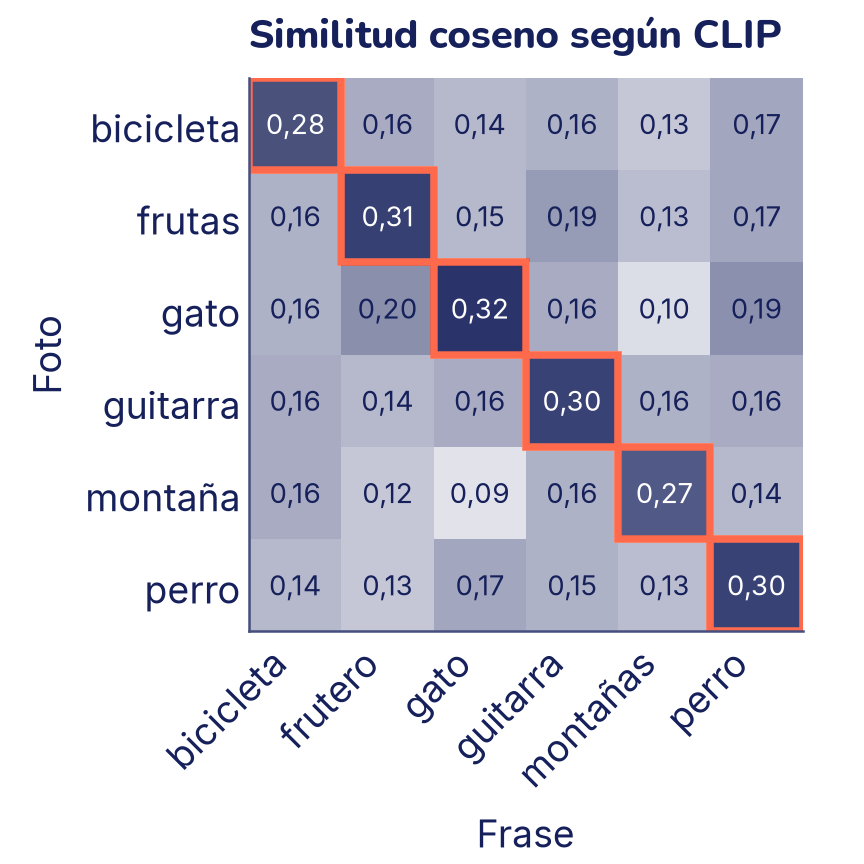

In [ ]:
from matplotlib.colors import LinearSegmentedColormap
from transformers import CLIPModel, CLIPProcessor

CLIP = "openai/clip-vit-base-patch32"
clip = CLIPModel.from_pretrained(CLIP).to(device).eval()
proc_clip = CLIPProcessor.from_pretrained(CLIP)

frases = ["a photo of a bicycle on the grass",  # una bici sobre el pasto
          "a bowl of fruit on a table",  # un frutero sobre una mesa
          "a cat sleeping on a chair",  # un gato durmiendo en una silla
          "the head of a guitar",  # el clavijero de una guitarra
          "snowy mountains and a lake",  # montañas nevadas y un lago
          "a dog lying by the sea"]  # un perro echado junto al mar
x = proc_clip(text=frases, images=list(fotos6.values()),
              return_tensors="pt", padding=True)
with torch.no_grad():
    salida = clip(**x.to(device))
# Una fila por foto y una columna por frase: escala · coseno
logits = salida.logits_per_image.cpu()
escala = clip.logit_scale.exp().item()
print(f"Escala aprendida: {escala:.0f}, o sea, tau = {1 / escala:.2f}")
sim = logits / escala
print("Frase elegida para cada foto:", logits.argmax(dim=1).tolist())

cortas = ["bicicleta", "frutero", "gato", "guitarra", "montañas",
          "perro"]
fig, eje = plt.subplots(figsize=(4.8, 4.8))
eje.imshow(sim, cmap=LinearSegmentedColormap.from_list(
    "tinta", ["white", "C0"]), vmin=0.05, vmax=0.35)
for i in range(6):
    for j in range(6):
        eje.text(j, i, f"{sim[i, j]:.2f}".replace(".", ","),
                 ha="center", va="center", fontsize=11,
                 color="white" if sim[i, j] > 0.22 else "C0")
    # La pareja correcta de cada fila, con borde coral
    eje.add_patch(plt.Rectangle((i - 0.5, i - 0.5), 1, 1, fill=False,
                                edgecolor="C1", linewidth=3))
eje.grid(False)
eje.set_xticks(range(6), cortas, rotation=45, ha="right")
eje.set_yticks(range(6), list(fotos6))
eje.set_xlabel("Frase")
eje.set_ylabel("Foto")
eje.set_title("Similitud coseno según CLIP")
plt.show()

CLIP elige la frase correcta para las seis fotos: la diagonal gana en cada fila. Fíjate en que las similitudes son números pequeños: la diagonal está entre 0,27 y 0,32, y el resto entre 0,09 y 0,20. Por eso hace falta la temperatura: dividir por τ = 0,01 (multiplicar por 100) convierte una diferencia de 0,1 en una de 10 antes del softmax. Calculemos la pérdida de este «lote» de seis y veamos el efecto de τ en la fila del gato:

In [ ]:
correctas = torch.arange(6)
perdida_filas = F.cross_entropy(logits, correctas)
perdida_columnas = F.cross_entropy(logits.T, correctas)
print(f"Pérdida contrastiva: "
      f"{(perdida_filas + perdida_columnas).item() / 2:.6f}")

for tau in [0.1, 0.03, 0.01]:
    p = (sim[2] / tau).softmax(dim=0)        # fila del gato
    print(f"tau = {tau:<4}: probabilidad de su frase {p[2]:.3f}, "
          f"pérdida de la fila {-p[2].log():.3f}")

Pérdida contrastiva: 0.000015
tau = 0.1 : probabilidad de su frase 0.485, pérdida de la fila 0.723
tau = 0.03: probabilidad de su frase 0.962, pérdida de la fila 0.038
tau = 0.01: probabilidad de su frase 1.000, pérdida de la fila 0.000


Con τ = 0,1 el softmax distingue poco: la frase correcta se lleva menos de la mitad de la probabilidad. Con τ = 0,01 se lleva prácticamente toda. La pérdida de este lote es casi cero porque son seis fotos muy distintas; en el entrenamiento real, los lotes tenían 32 768 pares y muchos textos parecidos entre sí, y la tarea era mucho más difícil.

### Clasificar sin entrenar: *zero-shot*

Si CLIP sabe qué frase va con qué foto, puede **clasificar**: se escribe una frase por clase, con una **plantilla** como «a satellite photo of …», y cada foto se asigna a la frase más parecida. No se entrena nada ni se necesita una sola foto etiquetada: eso es clasificar **zero-shot** (con cero ejemplos).

Para codificar muchas fotos o frases sin calcular la matriz entera, `CLIPModel` tiene `get_image_features` y `get_text_features`. En `transformers` 5 devuelven un objeto, y el vector está en `pooler_output`; en versiones anteriores devolvían directamente el tensor.

In [ ]:
def codificar_fotos(fotos, lote=100):
    partes = []
    with torch.no_grad():
        for i in range(0, len(fotos), lote):
            x = proc_clip(images=fotos[i:i + lote], return_tensors="pt")
            salida = clip.get_image_features(**x.to(device))
            partes.append(salida.pooler_output.cpu())
    return F.normalize(torch.cat(partes), dim=1)


def codificar_textos(textos):
    x = proc_clip(text=textos, return_tensors="pt", padding=True)
    with torch.no_grad():
        salida = clip.get_text_features(**x.to(device))
    return F.normalize(salida.pooler_output.cpu(), dim=1)


from sklearn.metrics import confusion_matrix

c_val = codificar_fotos(fotos_val)
EN = ["a forest", "a highway", "a residential area", "a river"]
plantilla = "a satellite photo of {}"
t_clases = codificar_textos([plantilla.format(c) for c in EN])
pred = (c_val @ t_clases.T).argmax(dim=1)
print(f"Exactitud zero-shot: {(pred == y_val).float().mean():.3f}")
print("Matriz de confusión (filas: clase real):")
print(confusion_matrix(y_val, pred))

Exactitud zero-shot: 0.592
Matriz de confusión (filas: clase real):
[[51 46  2  1]
 [ 1 65 34  0]
 [ 0  0 99  1]
 [ 4 30 44 22]]


Sin ver una sola foto etiquetada de EuroSAT, CLIP acierta bastante más que el 25 % del azar. No llega al 93 % de la sonda lineal de ResNet-18, que aprendió con 400 fotos etiquetadas, pero no necesitó ninguna. La matriz de confusión muestra sus puntos débiles: casi la mitad de los bosques terminan como «autopista», y los ríos se le escapan a «zona residencial» o a «autopista»; solo reconoce 22 de 100. En los ejercicios vas a ver que el resultado depende mucho de cómo escribas la plantilla.

### Buscar fotos con texto

Como fotos y frases están en el mismo espacio, también se puede ir al revés: escribir una frase y buscar las fotos más parecidas. Es un buscador como el del tema «Embeddings», pero la consulta es texto y las respuestas son fotos.

Clases de las 5 más parecidas: ['autopista', 'río', 'río', 'río', 'río']


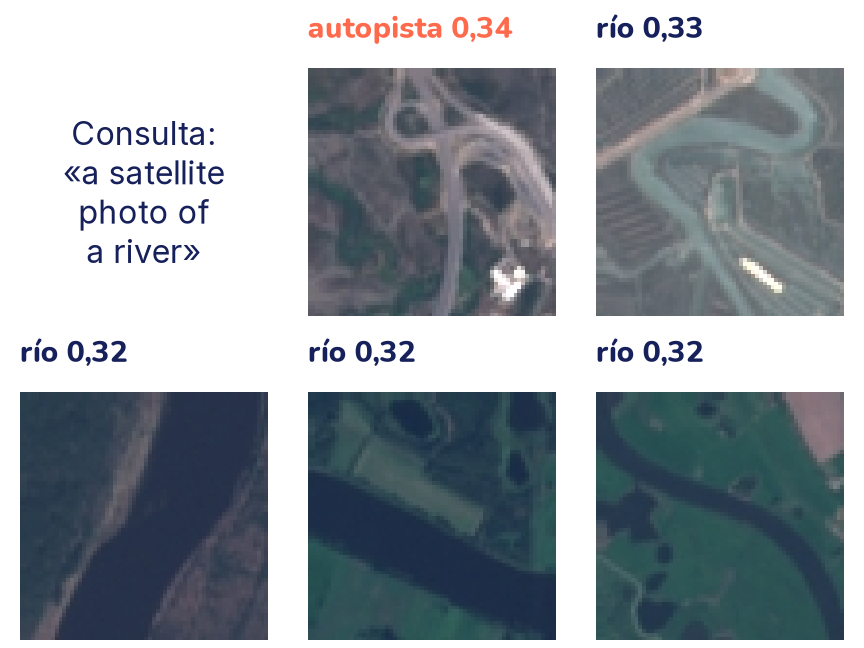

In [ ]:
consulta = "a satellite photo of a river"
s = (c_val @ codificar_textos([consulta]).T).squeeze(1)
mejores = s.topk(5).indices.tolist()
print("Clases de las 5 más parecidas:",
      [NOMBRES[y_val[k]] for k in mejores])

fig, ejes = plt.subplots(2, 3, figsize=(4.8, 3.6))
ejes[0, 0].text(0.5, 0.5, "Consulta:\n«a satellite\nphoto of\na river»",
                ha="center", va="center", fontsize=13, color="C0")
ejes[0, 0].axis("off")
for eje, k in zip(ejes.flat[1:], mejores):
    eje.imshow(fotos_val[k])
    # En coral, la que no es un río
    color = "C0" if NOMBRES[y_val[k]] == "río" else "C1"
    eje.set_title(f"{NOMBRES[y_val[k]]} {s[k]:.2f}".replace(".", ","),
                  fontsize=12, color=color)
    eje.axis("off")
plt.show()

Cuatro de las cinco fotos más parecidas son ríos. La primera es una autopista: otra vez la confusión de las franjas que cruzan la foto. Con miles de fotos, así funcionan los buscadores de fotos por texto: se codifican todas las fotos una vez, y cada búsqueda solo codifica la frase y compara.

## Lo que traen de fábrica: sesgos y licencias

Un modelo preentrenado trae lo bueno y lo malo de sus datos.

- **Vocabulario y mirada de sus datos.** Un clasificador de ImageNet solo conoce sus 1000 clases. CLIP aprendió de textos de internet en inglés, sobre todo de fotos subidas en países ricos: entiende peor otros idiomas, objetos y lugares que aparecen poco en internet, y repite los estereotipos de sus textos. Los autores de CLIP documentaron sesgos de este tipo al clasificar fotos de personas.
- **Lo que «ve» no es lo que crees.** Una red puede acertar por una pista equivocada: el fondo, el pasto, una marca de agua. Antes de confiar en un modelo, mira sus errores con tus propias fotos.
- **Licencias.** Los pesos de ResNet-18 se entrenaron con ImageNet, que solo permite usos no comerciales de investigación y educación. La ficha de CLIP dice que es un modelo para investigación y que desplegarlo en un producto queda fuera del uso previsto. DINOv2 y DeiT son Apache-2.0. Antes de usar un modelo en un proyecto, lee su ficha.

## Lo que aprendiste y lo que sigue

- Una red **preentrenada** con ImageNet ya sabe ver bordes, texturas y formas. Con **transfer learning** la reutilizas: entrenas **solo una cabeza nueva** sobre sus variables congeladas, o haces un **ajuste completo** con una tasa de aprendizaje pequeña. Aquí: 93,8 % con la cabeza, 96,3 % con el ajuste completo.
- Con 20 fotos por clase, el transfer superó a una CNN entrenada desde cero con 100. Siempre se prepara la foto con `pesos.transforms()`.
- El **aprendizaje autosupervisado** aprende sin etiquetas. **SimCLR** acerca dos vistas aumentadas de la misma foto y aleja las demás; **DINOv2** aprendió así con 142 millones de fotos, y sus variables con un simple **k-NN** clasificaron el 91 % de las fotos satelitales.
- Un **ViT** preentrenado clasifica fotos partiéndolas en parches, pero solo con las etiquetas que aprendió.
- **CLIP** pone fotos y frases en el mismo espacio. Se entrena con una **pérdida contrastiva** sobre la matriz de similitudes, y sirve para clasificar **zero-shot** con plantillas de texto y para **buscar fotos con texto**.

En el tema siguiente, «Detectar y segmentar», vas a usar redes preentrenadas como estas como base para algo más difícil que decir qué hay en una foto: decir **dónde** está cada cosa.

# Ejercicios

## Antes de empezar

Varios ejercicios usan las variables y funciones de la teoría: `eurosat`, `CLASES`, `NOMBRES`, `fotos_ent`, `fotos_val`, `y_ent`, `y_val`, `pesos`, `preparar`, `x_ent`, `x_val`, `red` (ResNet-18 sin su cabeza), `variables`, `v_ent`, `v_val`, `entrenar`, `evaluar`, `d_ent`, `d_val` (las variables de DINOv2), `fotos6`, `frases`, `proc_vit`, `vit`, `clip`, `proc_clip`, `codificar_fotos`, `codificar_textos`, `c_val` y `EN`. En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Los modelos ocupan cerca de 800 MB entre todos; la primera vez tardan un poco en descargarse.

Intenta cada ejercicio antes de abrir la respuesta: equivocarse primero y corregir después es como se aprende de verdad.

## Ejercicios

### 1. ¿Qué harías?

Para cada caso, di si conviene entrenar **solo la cabeza**, hacer un **ajuste completo**, usar **CLIP zero-shot** o entrenar **desde cero**, y por qué.

1. Tienes 30 fotos de cada una de tres plantas de tu jardín y una computadora sin GPU.
2. Tienes 20 000 radiografías etiquetadas y acceso a una GPU durante una semana.
3. Quieres ordenar las fotos de tu celular en «comida», «paisajes» y «mascotas» y no quieres etiquetar ninguna.
4. Tienes 5000 fotos de microscopio de un tipo de célula que no se parece a nada de internet, y una GPU.

<details>
<summary>Respuesta</summary>

1. **Solo la cabeza** (o una sonda lineal): con 30 fotos por clase, un ajuste completo puede sobreajustar, y calcular las variables una vez es barato sin GPU. Si después quieres un poco más, puedes ajustar solo las últimas capas.
2. **Ajuste completo** desde una red preentrenada: con muchos datos y GPU, retocar todos los filtros suele dar lo mejor. Entrenar desde cero también sería posible, pero partir de pesos preentrenados casi nunca empeora y converge más rápido.
3. **CLIP zero-shot**, con plantillas como «a photo of food». Son clases comunes en internet, justo lo que CLIP vio.
4. **Ajuste completo** de una red preentrenada, probablemente con varias épocas. Las fotos se parecen poco a ImageNet y a internet, así que la cabeza sola y CLIP zero-shot rendirían peor; aun así, los bordes y texturas de las primeras capas sirven. Desde cero también es razonable con 5000 fotos; lo correcto es probar las dos opciones y medir en validación.

</details>

### 2. Contar lo que se entrena

Carga una ResNet-18 nueva con una cabeza de 4 clases y cuenta los parámetros entrenables en tres casos: todo, solo la cabeza, y la cabeza más el último bloque (`layer4`). Para congelar, pon `requires_grad = False` a todos los parámetros y después devuélvelo a `True` en los que quieres entrenar.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
modelo = resnet18(weights=pesos)
modelo.fc = nn.Linear(512, 4)


def entrenables(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


total = entrenables(modelo)
print(f"Todo:                  {total:>10,}".replace(",", " "))
for p in modelo.parameters():
    p.requires_grad = False
for p in modelo.fc.parameters():
    p.requires_grad = True
print(f"Solo la cabeza:        {entrenables(modelo):>10,}"
      .replace(",", " "))
for p in modelo.layer4.parameters():
    p.requires_grad = True
n = entrenables(modelo)
print(f"layer4 y la cabeza:    {n:>10,}".replace(",", " "),
      f"({n / total:.0%})")

<details>
<summary>Respuesta</summary>

La cabeza tiene 512 · 4 + 4 = 2052 parámetros, menos del 0,02 % de la red. El último bloque solo ya tiene cerca de tres cuartos de todos: las capas finales de una CNN tienen muchos canales, y cada filtro de 3 × 3 × 512 tiene 4608 pesos. Ajustar «solo las últimas capas» ahorra cálculo (el gradiente no tiene que bajar hasta el principio), pero no tantos parámetros como podrías pensar.

</details>

### 3. Cabeza o ajuste completo, con pocas fotos

En la teoría, con 100 fotos por clase, el ajuste completo le ganó a la cabeza sola. ¿Pasa lo mismo con **10 fotos por clase**? Entrena una sonda lineal con las variables de esas 40 fotos y, aparte, ajusta toda la red 5 épocas con ellas (lotes de 8, tasa 0,0001). Compara las dos en las 400 fotos de validación. `entrenar` pide un cargador de validación; como no vamos a mirar esos números, le pasamos el mismo de entrenamiento con `mostrar=False`, y medimos la validación una sola vez al final con `evaluar`.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
sel = torch.cat([torch.arange(k * 100, k * 100 + 10) for k in range(4)])
sonda = LogisticRegression(max_iter=2000)
sonda.fit(v_ent[sel].numpy(), y_ent[sel].numpy())
print(f"Solo la cabeza:  {sonda.score(v_val.numpy(), y_val.numpy()):.3f}")

torch.manual_seed(0)
pocas = resnet18(weights=pesos)
pocas.fc = nn.Linear(512, 4)
cargador_pocas = DataLoader(TensorDataset(x_ent[sel], y_ent[sel]),
                            batch_size=8, shuffle=True,
                            generator=torch.Generator().manual_seed(0))
entrenar(pocas, cargador_pocas, cargador_pocas, epocas=5,
         optimizador=torch.optim.Adam(pocas.parameters(), lr=1e-4),
         dispositivo=device, mostrar=False)
cargador_val = DataLoader(TensorDataset(x_val, y_val), batch_size=100)
_, exactitud = evaluar(pocas, cargador_val, nn.CrossEntropyLoss(), device)
print(f"Ajuste completo: {exactitud:.3f}")

<details>
<summary>Respuesta</summary>

Con 10 fotos por clase las dos formas quedan cerca. El ajuste completo gana por poco, pero con 40 fotos y 11 millones de parámetros el resultado depende mucho de la semilla y de la tasa, y cuesta mucho más tiempo. Con pocas fotos, la cabeza sola es la apuesta segura; el ajuste completo rinde más cuando hay más datos (como en la teoría) o cuando las fotos se parecen poco a las del preentrenamiento.

</details>

### 4. Diseña plantillas para CLIP

En la teoría, la plantilla «a satellite photo of …» dio la exactitud zero-shot de EuroSAT. Prueba estas plantillas con las mismas cuatro clases de `EN` y mide la exactitud de cada una:

- solo el nombre de la clase, sin plantilla;
- la de la teoría, «a satellite photo of …»;
- «a satellite photo of ….» (con punto final);
- «a photo of ….»;
- «an aerial view of …».

Después prueba el **promedio de plantillas**: codifica las cinco frases de cada clase, promedia sus vectores, normaliza y clasifica con ese vector promedio.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
plantillas = ["{}", "a satellite photo of {}", "a satellite photo of {}.",
              "a photo of {}.", "an aerial view of {}."]


def exactitud_zero_shot(t):
    pred = (c_val @ t.T).argmax(dim=1)
    return (pred == y_val).float().mean().item()


vectores = []
for p in plantillas:
    t = codificar_textos([p.format(c) for c in EN])
    vectores.append(t)
    print(f"{p!r:28s} {exactitud_zero_shot(t):.3f}")

promedio = F.normalize(torch.stack(vectores).mean(dim=0), dim=1)
print(f"{'promedio de las cinco':28s} {exactitud_zero_shot(promedio):.3f}")

<details>
<summary>Respuesta</summary>

Un detalle tan chico como el **punto final** cambia mucho la exactitud: CLIP no «entiende» la frase como una persona, la convierte en un vector que depende de cada token. Por eso hay que probar varias plantillas y **medir** con fotos etiquetadas, aunque sean pocas. Promediar plantillas suele dar un resultado más estable que elegir una sola (los autores de CLIP promediaron 80 plantillas para ImageNet), pero aquí no le gana a la mejor plantilla: tampoco es magia. Ojo: si eliges la plantilla mirando la exactitud de prueba, esa exactitud ya no es una medida honesta; lo correcto es elegirla con un conjunto de validación aparte.

</details>

### 5. La pérdida contrastiva a mano

Un lote de dos fotos y sus dos textos tiene esta matriz de similitudes coseno (fila: foto; columna: texto):

| | texto 1 | texto 2 |
|---|---|---|
| foto 1 | 0,30 | 0,10 |
| foto 2 | 0,20 | 0,25 |

Con τ = 0,1, calcula a mano la probabilidad que le da cada foto a su texto correcto (softmax por filas) y la pérdida por filas, *L* = −(log *p*₁₁ + log *p*₂₂) / 2. Después compruébalo con `F.cross_entropy`. ¿Qué pasa con la pérdida si τ = 0,01?

<details>
<summary>Respuesta</summary>

Dividir por τ = 0,1 multiplica por 10: la fila 1 queda (3; 1) y la fila 2, (2; 2,5).

- *p*₁₁ = e³ / (e³ + e¹) = 1 / (1 + e⁻²) ≈ 1 / 1,135 ≈ **0,881**
- *p*₂₂ = e²·⁵ / (e² + e²·⁵) = 1 / (1 + e⁻⁰·⁵) ≈ 1 / 1,607 ≈ **0,622**
- *L* = −(ln 0,881 + ln 0,622) / 2 ≈ (0,127 + 0,475) / 2 ≈ **0,301**

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
s = torch.tensor([[0.30, 0.10], [0.20, 0.25]])
correctas = torch.tensor([0, 1])
for tau in [0.1, 0.01]:
    p = (s / tau).softmax(dim=1)
    perdida = F.cross_entropy(s / tau, correctas)
    print(f"tau = {tau}: p11 = {p[0, 0]:.3f}, p22 = {p[1, 1]:.3f}, "
          f"pérdida = {perdida:.3f}")

<details>
<summary>Respuesta (sigue)</summary>

Con τ = 0,01, diferencias de similitud de 0,05 se vuelven diferencias de 5 antes del softmax, y las dos fotos dan casi toda la probabilidad a su texto: la pérdida baja casi a cero **sin que cambie ningún vector**. Por eso la temperatura se aprende junto con la red, y por eso una pérdida chica solo se puede comparar con otra calculada con la misma τ.

</details>

### 6. ¿CLIP entiende español?

CLIP se entrenó con textos en inglés. Repite la matriz de la teoría con las frases traducidas al español («una foto de una bicicleta sobre el pasto», «un frutero sobre una mesa», «un gato durmiendo en una silla», «el clavijero de una guitarra», «montañas nevadas y una laguna», «un perro echado junto al mar»). ¿Sigue ganando la diagonal? ¿Por cuánto? Después prueba la clasificación zero-shot de EuroSAT con la plantilla «una foto satelital de …» y las clases en español.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
frases_es = ["una foto de una bicicleta sobre el pasto",
             "un frutero sobre una mesa",
             "un gato durmiendo en una silla",
             "el clavijero de una guitarra",
             "montañas nevadas y una laguna",
             "un perro echado junto al mar"]
for idioma, textos in [("inglés", frases), ("español", frases_es)]:
    t = codificar_textos(textos)
    s6 = codificar_fotos(list(fotos6.values())) @ t.T
    diagonal = s6.diagonal()
    # El mayor valor de cada fila fuera de la diagonal
    otros = (s6 - 9 * torch.eye(6)).max(dim=1).values
    print(f"{idioma:8s} elige {s6.argmax(dim=1).tolist()}  "
          f"diagonal {diagonal.mean():.3f}  "
          f"margen medio {(diagonal - otros).mean():.3f}")

ES = ["un bosque", "una autopista", "una zona residencial", "un río"]
t = codificar_textos([f"una foto satelital de {c}" for c in ES])
pred = (c_val @ t.T).argmax(dim=1)
print(f"EuroSAT en español: {(pred == y_val).float().mean():.3f}")

<details>
<summary>Respuesta</summary>

Con estas seis fotos tan distintas, CLIP todavía acierta las seis en español, pero con similitudes más bajas y menos margen sobre la segunda frase: muchas palabras («bicicleta», «guitarra», «gato») comparten pedazos con el inglés o aparecieron en textos de internet. En EuroSAT, la plantilla en español dio casi lo mismo que la de la teoría en inglés (0,598 frente a 0,592): con estas clases, CLIP se equivoca por otras razones. Que acierte en estos casos no quiere decir que entienda español; con frases que no se parecen al inglés le puede ir mucho peor. Para otro idioma conviene traducir las frases al inglés o usar un CLIP multilingüe, y siempre medir.

</details>

### 7. ¿Cuántos vecinos?

Clasifica las fotos de validación de EuroSAT con k-NN usando las variables de DINOv2 (`d_ent`, `d_val`) y las de ResNet-18 (`v_ent`, `v_val`), con k = 1, 5 y 15. ¿Qué variables funcionan mejor? ¿Cambia mucho con k?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for nombre, a, b in [("DINOv2", d_ent, d_val), ("ResNet-18", v_ent, v_val)]:
    fila = []
    for k in [1, 5, 15]:
        knn = KNeighborsClassifier(n_neighbors=k, metric="cosine")
        knn.fit(a.numpy(), y_ent.numpy())
        fila.append(f"k = {k:2d}: {knn.score(b.numpy(), y_val.numpy()):.3f}")
    print(f"{nombre:10s}", "   ".join(fila))

<details>
<summary>Respuesta</summary>

DINOv2 gana con los tres valores de k, aunque nunca vio una etiqueta: el autoaprendizaje con muchísimas fotos dio variables por lo menos tan útiles como las de una red entrenada con etiquetas. Con k = 1 una sola vecina equivocada decide; con k = 5 la votación corrige algunos errores; con k más grande se empiezan a colar vecinas de otras clases. Elegir k mirando la prueba tiene el mismo problema que en el ejercicio 4: para elegirlo bien hace falta validación (tema 7).

</details>

### 8. Un ViT de ImageNet frente a fotos satelitales

Pasa ocho fotos de validación de EuroSAT (dos de cada clase: las de índice 0, 50, 100, 150, 200, 250, 300 y 350) por DeiT-tiny y mira qué etiqueta de ImageNet elige para cada una. ¿Por qué pasa esto? ¿Qué harías para que DeiT-tiny sirva para EuroSAT?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
ocho = [fotos_val[i] for i in range(0, 400, 50)]
x = proc_vit(images=ocho, return_tensors="pt")
with torch.no_grad():
    elegidas = vit(**x.to(device)).logits.argmax(dim=1).tolist()
for i, k in zip(range(0, 400, 50), elegidas):
    etiqueta = vit.config.id2label[k].split(",")[0]
    print(f"{NOMBRES[y_val[i]]:12s} -> {etiqueta}")

<details>
<summary>Respuesta</summary>

Las respuestas son absurdas (gusanos, peces, instrumentos), pero tienen lógica: DeiT-tiny **tiene que** elegir una de sus 1000 clases de ImageNet, y ninguna es «río visto desde un satélite». Elige la clase cuyas texturas se parecen más: un río serpenteante se parece a un gusano; un tejido de techos, a un tejado. Para usarlo con EuroSAT, hay que cambiarle la cabeza por una de 4 clases y entrenarla (o ajustar toda la red), exactamente como hiciste con ResNet-18.

</details>

## Mini-proyecto: tu propio clasificador de objetos

Vas a construir un clasificador de **3 a 5 objetos cotidianos** con **tus propias fotos** y comparar dos formas de hacerlo: transfer learning con ResNet-18 y CLIP zero-shot.

1. **Saca las fotos.** Elige de 3 a 5 objetos de tu casa (una taza, un cuaderno, tus llaves, un par de zapatillas…). Saca unas **50 fotos de cada uno** con tu celular: desde distintos ángulos, con distinta luz, sobre distintos fondos y a distintas distancias. Si todas las tazas están sobre la misma mesa y todos los cuadernos sobre la cama, el modelo puede aprender a reconocer la mesa y la cama, no los objetos. No saques fotos de personas.
2. **Ordénalas en carpetas**, una por objeto, dentro de una carpeta `mis_fotos`: `mis_fotos/taza/`, `mis_fotos/cuaderno/`, etc. En Colab, súbela comprimida en un .zip (desde el panel de archivos) y descomprímela.
3. **Transfer learning.** Calcula las variables de ResNet-18 de cada foto y mide una sonda lineal con **validación cruzada** de 5 pliegues (tema 7): con 50 fotos por clase no conviene separar un solo conjunto de prueba.
4. **CLIP zero-shot.** Escribe en inglés una frase por objeto («a photo of a mug») y clasifica cada foto con la más parecida.
5. **Compara** las dos exactitudes, mira la matriz de confusión y **mira las fotos que fallan**. ¿Qué tienen en común? Prueba al menos dos plantillas para CLIP.
6. **Extra:** ajusta toda la red unas épocas (como en la teoría) separando un 20 % de las fotos para validación, y compara.

El código lee cualquier carpeta con esa forma. Para que puedas probarlo antes de sacar tus fotos, si no encuentra `mis_fotos` arma una de prueba con 20 fotos de EuroSAT por clase que no usamos en la teoría.

In [ ]:
from PIL import ImageOps
from sklearn.model_selection import cross_val_score

CARPETA = Path("mis_fotos")

# Solo para probar el código sin tus fotos: 20 fotos de EuroSAT por clase
if not CARPETA.exists():
    usadas = set(idx_ent) | set(idx_val)
    rng = np.random.default_rng(0)
    for clase, nombre in zip(CLASES, NOMBRES):
        de_la_clase = np.flatnonzero(
            etiquetas == eurosat.class_to_idx[clase])
        libres = [i for i in de_la_clase if i not in usadas]
        (CARPETA / nombre).mkdir(parents=True)
        for k, i in enumerate(rng.choice(libres, size=20, replace=False)):
            eurosat[i][0].save(CARPETA / nombre / f"{k:02d}.jpg")

clases = sorted(d.name for d in CARPETA.iterdir() if d.is_dir())
mis_fotos, mis_y = [], []
for k, clase in enumerate(clases):
    for archivo in sorted((CARPETA / clase).iterdir()):
        if archivo.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            foto = Image.open(archivo)
            # Gira según el celular y achica: las fotos son enormes
            foto = ImageOps.exif_transpose(foto).convert("RGB")
            foto.thumbnail((512, 512))
            mis_fotos.append(foto)
            mis_y.append(k)
mis_y = np.array(mis_y)
print("Clases:", clases)
print("Fotos por clase:", np.bincount(mis_y).tolist())

Clases: ['autopista', 'bosque', 'residencial', 'río']
Fotos por clase: [20, 20, 20, 20]


<details>
<summary>Resultados de referencia, con fotos de EuroSAT</summary>

Este código hace los pasos 3 a 5. Con tus fotos, cambia las frases de `DESCRIPCION` por las de tus objetos.

</details>

In [ ]:
# @title Resultados de referencia, con fotos de EuroSAT: código (doble clic para verlo)
from sklearn.metrics import confusion_matrix

# Paso 3: ResNet-18 congelada y sonda lineal, validación cruzada
x = torch.stack([preparar(f) for f in mis_fotos])
mis_v = variables(red, x).numpy()
puntajes = cross_val_score(LogisticRegression(max_iter=2000), mis_v,
                           mis_y, cv=5)
print(f"Transfer (5 pliegues): {puntajes.mean():.3f} "
      f"(de {puntajes.min():.3f} a {puntajes.max():.3f})")

# Paso 4: CLIP zero-shot, una frase en inglés por carpeta
DESCRIPCION = {"autopista": "a satellite photo of a highway",
               "bosque": "a satellite photo of a forest",
               "residencial": "a satellite photo of a residential area",
               "río": "a satellite photo of a river"}
t = codificar_textos([DESCRIPCION[c] for c in clases])
pred = (codificar_fotos(mis_fotos) @ t.T).argmax(dim=1).numpy()
print(f"CLIP zero-shot: {(pred == mis_y).mean():.3f}")

# Paso 5: dónde se equivoca CLIP
print(clases)
print(confusion_matrix(mis_y, pred))
fallas = np.flatnonzero(pred != mis_y)
print("Fotos que fallan:", [f"{clases[mis_y[i]]}->{clases[pred[i]]}"
                            for i in fallas[:4]])

<details>
<summary>Resultados de referencia, con fotos de EuroSAT (sigue)</summary>

- Con 20 fotos por clase, la sonda lineal sobre ResNet-18 acierta el 81 % en la validación cruzada (con 16 fotos por clase para entrenar en cada pliegue), y CLIP zero-shot apenas la mitad: con fotos satelitales, que CLIP vio poco, el transfer gana con claridad. Con fotos de objetos cotidianos, que abundan en internet, la distancia suele ser mucho menor.
- CLIP reconoce bien las autopistas y las zonas residenciales, pero manda casi todos los bosques y muchos ríos a «autopista»: la misma confusión de la teoría. Una plantilla mejor (ejercicio 4) ayudaría.
- Con tus fotos, la exactitud puede ser alta por una mala razón: si cada objeto se fotografió siempre sobre el mismo fondo. Una prueba honesta: saca 10 fotos nuevas de cada objeto en otro lugar y mide con ellas.

</details>

## Errores comunes

- **No usar el preprocesamiento del modelo.** Cada red preentrenada espera las fotos de cierto tamaño y normalizadas con cierta media y desviación. Usa `pesos.transforms()` en torchvision o el `AutoImageProcessor` del modelo en `transformers`; si no, la red recibe números que nunca vio y rinde mucho peor sin dar ningún error.
- **Olvidar `eval()` al extraer variables.** En modo de entrenamiento, BatchNorm usa las estadísticas del lote y las actualiza, y Dropout apaga neuronas: las variables cambian según con qué otras fotos vinieron.
- **Ajustar toda la red con una tasa de aprendizaje grande.** Con 0,001 o más, los primeros lotes pueden estropear los filtros preentrenados. Para el ajuste completo, empieza con 0,0001 o menos.
- **Creer que «congelado» quiere decir «sin cálculo».** Una red congelada no aprende, pero cada foto igual pasa por ella. Si la congelas entera, calcula sus variables una vez y guárdalas.
- **Olvidar cambiar la cabeza.** `resnet18(weights=...)` sale con 1000 salidas, las de ImageNet. Para tus clases hay que poner `modelo.fc = nn.Linear(512, número_de_clases)`.
- **Comparar similitudes de CLIP sin normalizar.** Los vectores de `get_image_features` y `get_text_features` no tienen largo 1: normalízalos antes del producto punto, o compararás largos además de direcciones.
- **Escribirle a CLIP en español.** Entiende sobre todo inglés: traduce tus frases o usa un modelo multilingüe, y mide.
- **Elegir la plantilla, k o las épocas mirando la prueba.** Lo que eliges con un conjunto ya no lo mide con honestidad: elige con validación y mide la prueba al final.
- **Fotos con el mismo fondo por clase.** El modelo aprende el atajo (el fondo) y no el objeto. Varía los fondos y prueba con fotos nuevas.
- **Usar un modelo sin leer su licencia.** «Se puede descargar» no quiere decir «se puede usar para cualquier cosa».

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Hacer transfer learning con una red preentrenada, entrenando solo la cabeza o ajustando toda la red (ejercicios 1, 2 y 3, y pasos 3 y 6 del mini-proyecto).
- Explicar el aprendizaje autosupervisado contrastivo y usar las variables de un modelo autosupervisado con k-NN (ejercicio 7).
- Usar un ViT preentrenado para clasificar y explicar su vocabulario cerrado (ejercicio 8).
- Clasificar sin entrenar con CLIP y diseñar plantillas (ejercicios 4 y 6, y paso 4 del mini-proyecto).
- Explicar la pérdida contrastiva como una matriz de similitudes y el papel de la temperatura (ejercicio 5 y la actividad).